In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import seaborn as sns

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.ExperimentSet import ExperimentSet
from src.Retrieval import Retrieval

plt.style.use('seaborn-v0_8-paper')

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
cvm = exset.get_retrieval('default').cvm.drop_vars(['delx', 'dely'])
cvm['cloud_top_heights'] = cvm.z.where(cvm.cloud_volume_mask == 1).max(dim="z")
cvm['distance_to_cloud_top'] = cvm.z - cvm.cloud_top_heights
cvm['cloud_base_heights'] = cvm.z.where(cvm.cloud_volume_mask == 1).min(dim="z")
cvm['distance_to_cloud_base'] = cvm.z - cvm.cloud_base_heights
distance_to_cloud = cvm.distance_to_cloud_base.clip(max=0) + cvm.distance_to_cloud_top.clip(min=0)
cvm["distance_to_cloud"] = distance_to_cloud
cvm = cvm.drop_vars(['cloud_top_heights', 'cloud_base_heights'])
cvm = cvm.to_dataframe()
df_list = []

for r in list(exset.retrievals.values()):
    tmp_ext = r.solvers_retrieval[0.67].medium['cloud'].extinction.copy(deep=True)
    df_tmp = tmp_ext.drop_vars(['reff', 'veff']).to_dataframe()
    df_tmp = df_tmp.join(cvm)
    df_tmp['source'] = r.exp_name
    df_list.append(df_tmp[df_tmp['extinction'] >= 0.3])

df = pd.concat(df_list)
# df = df.pivot(columns='source', values='extinction')
# df = df.join(exset.get_retrieval('default').cvm.drop_vars(['delx', 'dely']).to_dataframe())

df = df.reset_index()
df['x'] *= 1000
df['y'] *= 1000
df['z'] *= 1000

bins = np.arange(-50, 1451, 100)
df['altitude_bin'] = pd.cut(df['z'], bins=bins)

dtc_bins = np.arange(-0.45, 1.051, 0.1)
df['distance_to_cloud_bin'] = pd.cut(df['distance_to_cloud'], bins=dtc_bins)

/tmp/ipykernel_1420426/2393578665.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_counts = df.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)
/tmp/ipykernel_1420426/2393578665.py:52: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_counts = df[df['cloud_volume_mask'] == 1].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)
/tmp/ipykernel_1420426/2393578665.py:78: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future d

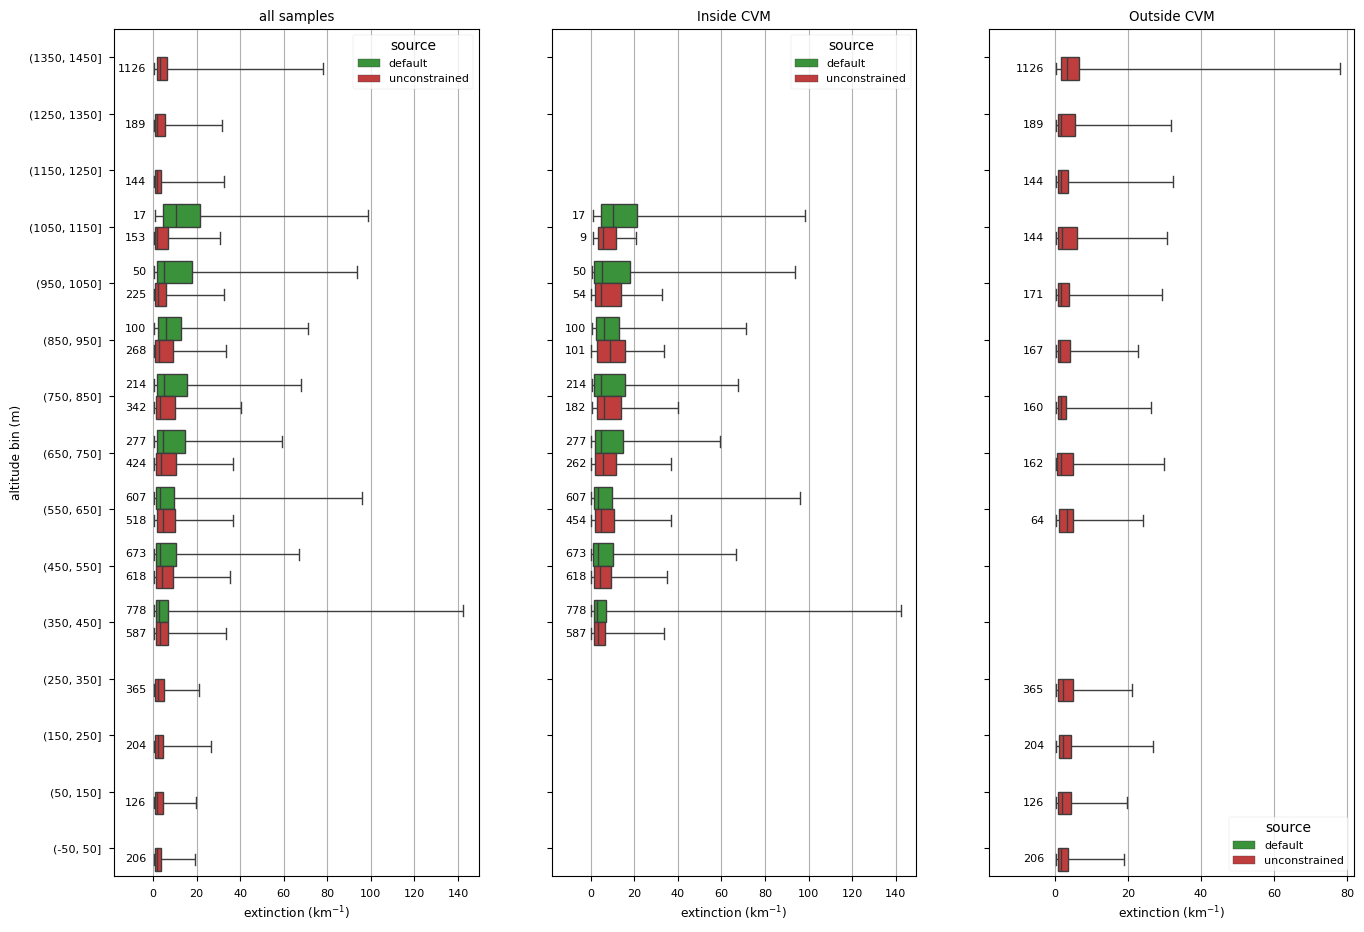

In [5]:
pltlist = ['default', 'unconstrained']

box_kwargs = {
    'x': 'extinction',
    'y': 'altitude_bin',
    'hue': 'source',
    'hue_order': pltlist,
    'palette': {
        'in situ': 'white',
        'default': 'tab:green',
        'periodic': 'tab:blue',
        'unconstrained': 'tab:red',
        'aod0p150': 'tab:orange',
        'surf4p0': 'tab:purple'
    },
    'order': [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)],
    'whis':(0, 100),
}

f, ax = plt.subplots(1, 3, figsize=(16,11), sharex=False, sharey=True)
sns.boxplot(df[df['source'].isin(pltlist)], ax=ax[0], **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax[0].text(-3, y_pos, f'{count}', ha='right', va='center', fontsize=8)

ax[0].set_xlim(-18, None)
ax[0].set_ylabel('altitude bin (m)')
ax[0].set_xlabel(r'extinction (km$^{-1}$)')
ax[0].set_title('all samples')
ax[0].grid(axis='x')

sns.boxplot(df[(df['source'].isin(pltlist)) & (df['cloud_volume_mask'] == 1)], ax=ax[1], **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df[df['cloud_volume_mask'] == 1].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax[1].text(-2, y_pos, f'{count}', ha='right', va='center', fontsize=8)

ax[1].set_xlim(-18, None)
# ax[1].set_ylabel('altitude bin (m)')
ax[1].set_xlabel(r'extinction (km$^{-1}$)')
ax[1].set_title('Inside CVM')
ax[1].grid(axis='x')

sns.boxplot(df[(df['source'].isin(pltlist)) & (df['cloud_volume_mask'] == 0)], ax=ax[2], **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df[df['cloud_volume_mask'] == 0].groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax[2].text(-3, y_pos, f'{count}', ha='right', va='center', fontsize=8)

ax[2].set_xlim(-18, None)
# ax[1].set_ylabel('altitude bin (m)')
ax[2].set_xlabel(r'extinction (km$^{-1}$)')
ax[2].set_title('Outside CVM')
ax[2].grid(axis='x')

<Axes: xlabel='extinction', ylabel='Count'>

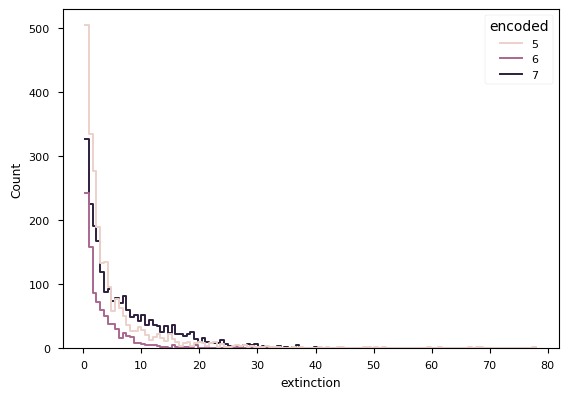

In [6]:
hist_kwargs = {
    'x':'extinction',
    'hue':'encoded',
    'element':'step',
    'fill':False
}
sns.histplot(data=df[df['source'] == 'unconstrained'], **hist_kwargs)

<Axes: xlabel='extinction', ylabel='distance_to_cloud_bin'>

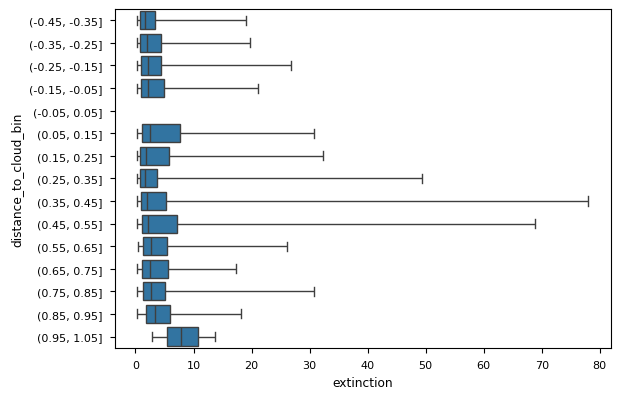

In [8]:
box_kwargs = {
    'x': 'extinction',
    'y': 'distance_to_cloud_bin',
    'whis':(0, 100),
}

sns.boxplot(df[(df['source'] == 'unconstrained') & (df['distance_to_cloud'] != 0)], **box_kwargs)


<Axes: xlabel='extinction', ylabel='distance_to_cloud'>

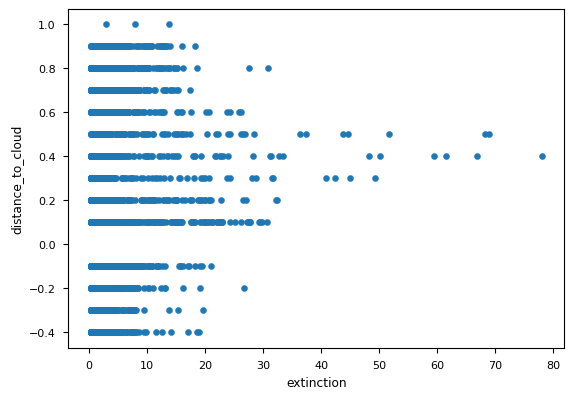

In [9]:
df[(df['source'] == 'unconstrained') & (df['distance_to_cloud'] != 0)].plot.scatter(x='extinction', y='distance_to_cloud')

<Axes: xlabel='extinction', ylabel='Count'>

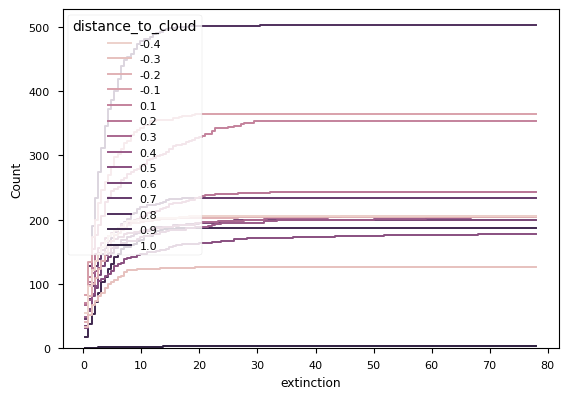

In [10]:
hist_kwargs = {
    'x':'extinction',
    'hue':'distance_to_cloud',
    'element':'step',
    'fill':False,
    'cumulative':True
}
df['distance_to_cloud'] = df['distance_to_cloud'].round(1)
sns.histplot(data=df[(df['source'] == 'unconstrained') & (df['distance_to_cloud'] != 0)], **hist_kwargs)